## Investment Universe and Data

Rather than attempting to reconstruct the historical composition of the S&P 500, the empirical analysis uses a fixed universe of large, established U.S. equities with sufficiently long historical records. 
The sample begins in 1992.

The selected universe consists of (some will be bannished from the list due to nissiing data):

```
AAPL MSFT IBM INTC CSCO ORCL TXN QCOM ADI AMAT KLAC LRCX MU HPQ ADP PAYX JPM BAC WFC C AXP GS USB PNC 
BK SCHW COF TROW NTRS BEN AFL JNJ MRK PFE BMY ABT MDT AMGN GILD LLY BAX BDX SYK UNH HUM CI CAH MCK PG 
KO PEP CL KMB GIS SYY HSY MO WMT COST TGT HD LOW MCD NKE DIS TJX XOM CVX COP SLB HAL OXY EOG CAT DE MMM 
HON GE EMR ETN PH ITW ROK GD LMT NOC FDX UPS UNP CSX NSC DUK SO AEP ED XEL PEG T VZ ECL APD SHW
``` 
Monthly security-level data are obtained from the CRSP database through WRDS. The dataset contains monthly total returns and market-capitalization information for each security.

The same stock universe is used to construct and compare four portfolio allocation methods:

- Equal Weight (EW)
- Capitalization Weight (CW)
- Equal Risk Contribution / Risk Parity (ERC)
- Global Minimum Variance (GMV)

The purpose of the experiment is to examine how different portfolio construction rules behave when applied to the same underlying set of assets. The S&P 500 and CRSP market indices are retained as external benchmarks for comparison.

In [5]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd 
import numpy as np 
import sys
sys.path.append("..")

from src import data_toolkit as dt
from src import portfolio_toolkit as pt
from pathlib import Path
import matplotlib.pyplot as plt

### Stock-Level CRSP Dataset

I use monthly security data downloaded from CRSP through WRDS for the selected universe of 40 U.S. equities.

The dataset is organized in long format, with one observation for each stock-month. The main variables are:

- **Ticker** — stock ticker identifying the company.
- **MthCalDt** — month-end calendar date.
- **MthPrc** — month-end stock price.
- **MthCap** — market capitalization at the end of the current month.
- **MthPrevCap** — market capitalization from the previous month.
- **MthRet** — monthly total stock return.


In [197]:
processed_dir = Path("../data/processed")
data = pd.read_csv(processed_dir/"100_stocks_dirty_1992-2026.csv")
data["MthCalDt"] = pd.to_datetime(
    data["MthCalDt"],
    format="%Y-%m-%d"
).dt.to_period("M")
data = data.drop_duplicates()
data

,PERMNO,HdrCUSIP,Ticker,PERMCO,MthCalDt,MthPrc,MthPrevCap,MthRet
0,10104,68389X10,ORCL,8045,1992-01,18.500,2.005611e+06,0.275862
1,10104,68389X10,ORCL,8045,1992-02,20.000,2.558883e+06,0.081081
2,10104,68389X10,ORCL,8045,1992-03,13.500,2.779740e+06,-0.325000
3,10104,68389X10,ORCL,8045,1992-04,13.875,1.876324e+06,0.027778
4,10104,68389X10,ORCL,8045,1992-05,14.875,1.928445e+06,0.072072
...,...,...,...,...,...,...,...,...
41136,92655,91324P10,UNH,7267,2026-02,293.270,2.599124e+08,0.022096
41137,92655,91324P10,UNH,7267,2026-03,270.590,2.656554e+08,-0.070184
41138,92655,91324P10,UNH,7267,2026-04,370.480,2.456080e+08,0.369156
41139,92655,91324P10,UNH,7267,2026-05,380.310,3.362758e+08,0.026533


In [199]:
data.duplicated(["Ticker", "MthCalDt"]).sum()

np.int64(0)

### Let's build returns & marketcap datasets:

In [200]:
rets = data.pivot(
    index="MthCalDt",
    columns="Ticker",
    values="MthRet"
)
rets.head()

Ticker,AAPL,ABT,ADI,ADP,AEP,AFL,AMAT,AMGN,APD,AXP,...,TXN,UNH,UNP,UPS,USB,VZ,WFC,WMT,XEL,XOM
MthCalDt,,,,,,,,,,,,,,,,,,,,,
1992-01,0.148559,-0.069056,0.065789,0.200000,-0.054745,-0.012552,0.088652,-0.069307,0.071066,0.006098,...,0.162602,0.117450,-0.120773,-0.507463,NaN,NaN,0.129310,-0.084926,NaN,NaN
1992-02,0.044422,-0.003914,-0.037037,-0.033333,-0.028022,0.020353,0.133550,-0.074468,0.080569,0.018182,...,0.048951,-0.039039,0.043956,0.060606,NaN,NaN,0.062977,0.002320,NaN,NaN
1992-03,-0.137037,-0.041257,0.000000,-0.172414,-0.004049,-0.083333,-0.083333,-0.042146,-0.004094,0.101126,...,-0.125290,-0.009375,-0.003406,-0.171429,NaN,NaN,0.012567,-0.012926,NaN,NaN
1992-04,0.032189,0.087059,0.064103,-0.250000,0.040650,0.036364,-0.072100,-0.104000,0.106195,-0.016393,...,0.061303,-0.034330,0.132979,NaN,NaN,NaN,0.130357,-0.018779,NaN,NaN
1992-05,-0.006237,0.009470,-0.048193,0.166667,0.007106,0.017156,0.216216,0.089286,0.005333,0.011111,...,0.086643,0.160131,0.000000,NaN,NaN,NaN,0.014218,0.014354,NaN,NaN


In [202]:
prev_caps = data.reset_index().pivot(
    index="MthCalDt",
    columns="Ticker",
    values="MthPrevCap"
)
prev_caps.head()

Ticker,AAPL,ABT,ADI,ADP,AEP,AFL,AMAT,AMGN,APD,AXP,...,TXN,UNH,UNP,UPS,USB,VZ,WFC,WMT,XEL,XOM
MthCalDt,,,,,,,,,,,,,,,,,,,,,
1992-01,6679873.75,29290746.75,448799.00,21487.5,6320323.75,2437829.88,594702.75,9988698.0,4151775.0,9643569.00,...,2520147.00,2335128.0,10481496.75,83750.0,NaN,NaN,3013100.00,67613992.88,NaN,NaN
1992-02,7672227.50,27164376.75,478325.25,25785.0,5974320.63,2407229.50,655636.88,9296412.0,4446825.0,9702371.25,...,2929927.00,2609388.0,9215615.50,41250.0,NaN,NaN,3402725.00,61871827.88,NaN,NaN
1992-03,7998075.00,27058058.25,460609.50,24925.5,5697518.13,2448030.00,743197.50,8604126.0,4805100.0,9878778.00,...,3073350.00,2507520.0,9620697.50,43750.0,NaN,NaN,3617018.75,62015382.00,NaN,NaN
1992-04,6999553.00,25941165.00,462861.75,20628.0,5674451.25,2244027.50,681264.38,8331000.0,4790070.0,10800797.25,...,2679621.75,2691805.5,9519427.00,NaN,NaN,NaN,3636500.00,61162630.50,NaN,NaN
1992-05,7224860.50,28067490.00,492532.38,15471.0,5905120.00,2325628.50,640155.50,7464576.0,5298750.0,10623735.00,...,2843889.75,2598399.0,10785308.25,NaN,NaN,NaN,4110543.75,60014036.50,NaN,NaN


we check for missing data:

In [204]:
ret_missing = rets.isna().sum().sort_values()
ret_missing

Ticker
AAPL      0
NSC       0
NOC       0
NKE       0
MU        0
       ... 
XOM      95
VZ      102
CVX     117
HPQ     124
SCHW    167
Length: 102, dtype: int64

In [206]:
cap_missing = prev_caps.isna().sum().sort_values()
cap_missing

Ticker
AAPL      0
NSC       0
NOC       0
NKE       0
MU        0
       ... 
XOM      95
VZ      102
CVX     117
HPQ     124
SCHW    167
Length: 102, dtype: int64

In [208]:
clean_stocks = rets.columns[
    (rets.isna().sum() == 0) &
    (prev_caps.isna().sum() == 0)
]

len(clean_stocks)

81

In [209]:
rets = rets[clean_stocks]
prev_caps = prev_caps[clean_stocks]

In [210]:
mc_weights = prev_caps.div(prev_caps.sum(axis = 'columns'), axis = 0)
vw_rets = (rets * mc_weights).sum(axis = 1)
vw_rets.head()

MthCalDt
1992-01   -0.023311
1992-02    0.008675
1992-03   -0.023744
1992-04    0.016577
1992-05    0.020211
Freq: M, dtype: float64

<Axes: title={'center': 'MC slice view - 81 stocks'}, xlabel='MthCalDt'>

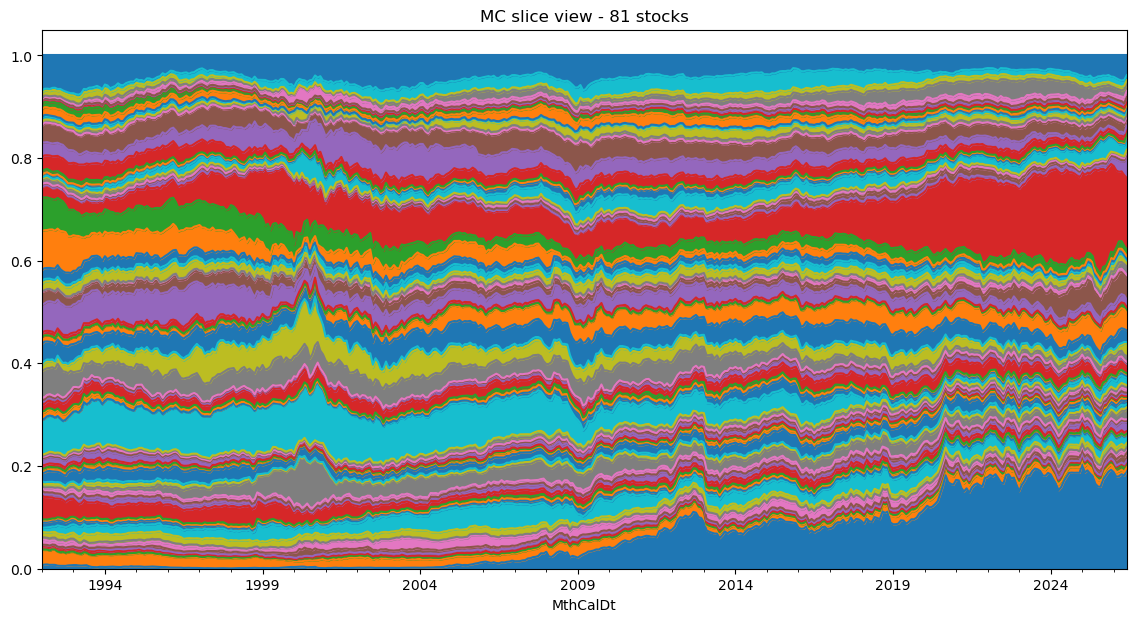

In [213]:
mc_weights.plot.area( figsize=(14, 7), stacked=True, legend = False, title = "MC slice view - 81 stocks")

### Now, we build the EW dataset:

In [214]:
ew_weights = np.repeat(1/rets.shape[1], rets.shape[1])
ew_rets = (rets*ew_weights).sum(axis = 1)
ew_rets.head()

MthCalDt
1992-01    0.019111
1992-02    0.010603
1992-03   -0.025601
1992-04    0.011762
1992-05    0.024105
Freq: M, dtype: float64

### Compare Results:

<Axes: title={'center': '81 Stock Index Cumulativ \n EW vs CW'}, xlabel='MthCalDt'>

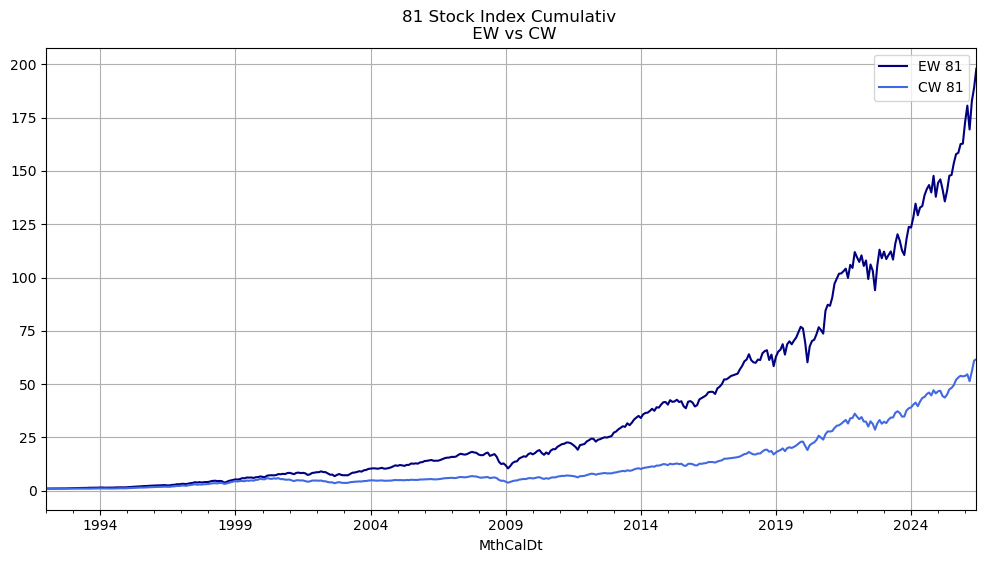

In [216]:
btr_1 = pd.DataFrame({
    "EW 81": ew_rets,
    "CW 81": vw_rets
})
(btr_1+1).cumprod().plot(figsize = (12,6), legend = True, grid = True, color=["navy", "royalblue"], 
                         title = "81 Stock Index Cumulativ \n EW vs CW")

In [219]:
pt.summary_stats(btr_1)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW 81,0.165649,0.146252,-0.455758,4.317021,0.059792,0.088997,0.925527,-0.425269
CW 81,0.126901,0.144688,-0.394437,3.563234,0.061822,0.087011,0.697663,-0.447946


### Preliminary Results: Naive Diversification

The first stock-level comparison provides strong preliminary support for the idea of naive diversification. Over the full sample, the equal-weighted portfolio substantially outperforms the capitalization-weighted portfolio.

EW delivers a higher annualized return of approximately **16.56%** versus **12.69%** for CW, while annualized volatilities are comparable. As a result, EW also achieves a materially higher Sharpe ratio, **0.926** compared with **0.698** for CW, and a slightly smaller maximum drawdown.

These results suggest that, within this fixed 81-stock universe, simply allocating capital equally across stocks produced both stronger returns and better risk-adjusted performance. 

## Risk Concentration & Risk Parity Portfolio 

### Let's compute the effective number of constituents:
We take each point in time and compute the ENC for the Value-Weighted portfolio. 
```
ENC is a financial metric that measures true portfolio or index diversification. It shows how many equally weighted positions your portfolio actually behaves like.
```
The effective number of constituents measures portfolio concentration and is defined as:

$$
ENC_t = \frac{1}{\sum_{i=1}^{N} w_{i,t}^2}
$$

where $w_{i,t}$ is the portfolio weight of asset $i$ at time $t$.

A higher $ENC$ indicates a more evenly distributed portfolio, while a lower $ENC$ indicates greater concentration in a smaller number of assets.

For an equally weighted portfolio:

$$
w_i = \frac{1}{N}
$$

Thus, for an equal-weighted portfolio of 40 stocks:

$$
ENC_{EW}=40
$$

For the capitalization-weighted portfolio, $ENC$ will generally be below 40 because the portfolio assigns larger weights to larger companies.

<Axes: title={'center': 'Effective Number of Constituents (81 stocks)\n EW vs CW'}, xlabel='MthCalDt'>

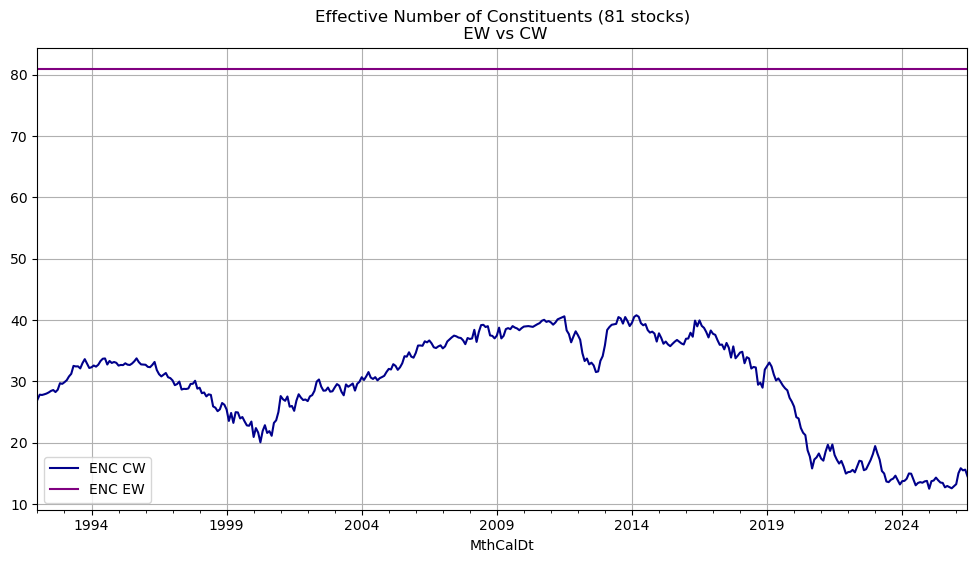

In [220]:
enc_mc = 1/((mc_weights**2).sum(axis =1))
enc = pd.DataFrame({
    "ENC CW": enc_mc,
    "ENC EW": 81
    
})
enc.plot(figsize = (12,6), grid = True, legend = True, title = "Effective Number of Constituents (81 stocks)\n EW vs CW",
        color = ['darkblue', 'purple'])

#### What does this mean ?

Both 40-stock universe confirm the same qualitative result. While the equal-weighted portfolio always maintains an effective number of constituents of 40, both capitalization-weighted portfolios exhibit substantially lower ENC throughout the sample - both show a significant decline in effective diversification in recent years.
We loose the diversificationn benefits as we effectively hold few stocks in our value -weighted portfolio. 

### Let's move from capital concentration to risk concentration

Equal capital allocation does not necessarily imply equal diversification of risk, since individual stocks differ in volatility and correlation with the rest of the portfolio.

The next step is therefore to examine how portfolio risk is distributed across the 40 constituents over time.

For each month $t$, I estimate the covariance matrix using the preceding 36 months of stock returns:

$$
\Sigma_t = \operatorname{Cov}(R_{t-35},\ldots,R_t)
$$

Because the portfolio contains 40 assets while the estimation window contains only 36 monthly observations, the sample covariance matrix may be unstable or poorly conditioned. I therefore use a shrinkage covariance estimator.

Using the estimated covariance matrix and portfolio weights, the contribution of asset $i$ to portfolio variance is:

$$
w_{i,t}(\Sigma_t w_t)_i
$$

and its percentage contribution to total portfolio variance is:

$$
\frac{w_{i,t}(\Sigma_t w_t)_i}
{w_t^\top \Sigma_t w_t}
$$


I will use the function for risk contribution calculation from the module:

```python

def risk_contribution(w, cov):
    """
    Computes percentage contribution of each asset to portfolio variance.

    Inputs:
    - w: portfolio weights
    - cov: covariance matrix

    Returns:
    - percentage risk contributions, summing to 1
    """
    total_contrib = w * cov.dot(w)
    pct_contrib = total_contrib / total_contrib.sum()

    return pct_contrib


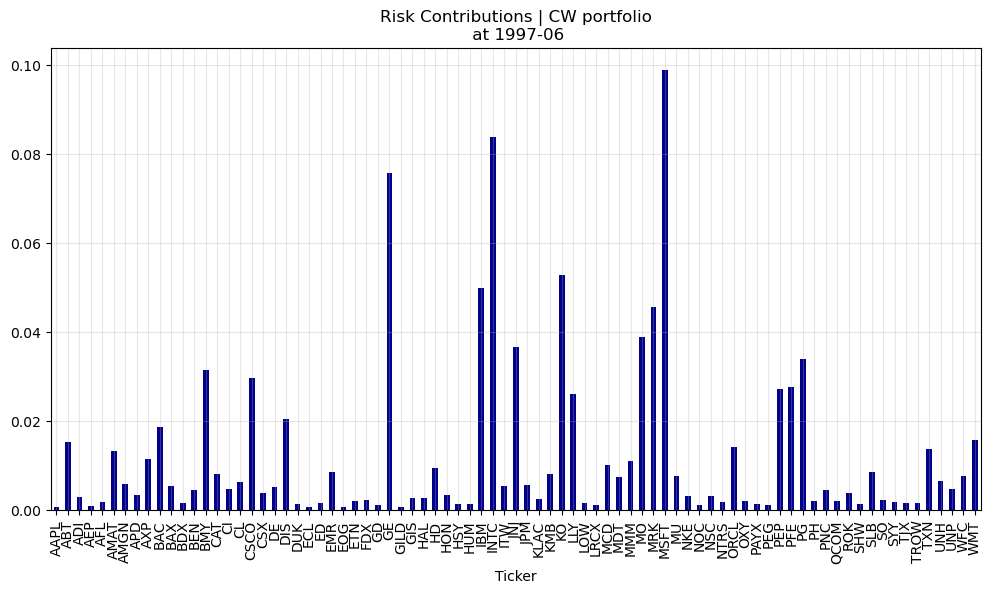

In [222]:
risk_contribs = {}

for i in range(36, len(rets)):
    date = rets.index[i]

    window = rets.iloc[i-36:i]
    cov = pt.shrinkage_cov(window)

    w = mc_weights.loc[date]

    risk_contribs[date] = pt.risk_contribution(w, cov)
    
risk_contribs = (pd.DataFrame(risk_contribs).T).dropna()

ax = risk_contribs.loc['1997-06'].plot.bar(figsize=(12,6), grid = True, color = 'darkblue', title = "Risk Contributions | CW portfolio\n at 1997-06")
ax.grid(alpha=0.3)

#### Above is the snapshot to get a sense of what a row in our dataframe looks like:
As we see, effectively, portfolio risk is concentrated in a few companies - contributors. 

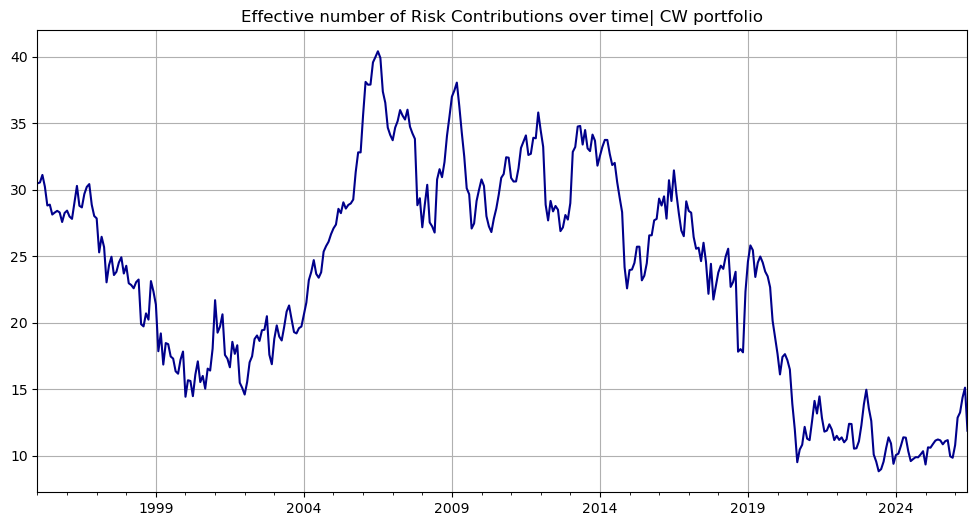

In [229]:
enrc_cw = 1 / (risk_contribs**2).sum(axis=1)
ax = enrc_cw.plot(figsize=(12,6), grid = True, color = 'darkblue', 
                  title = "Effective number of Risk Contributions over time| CW portfolio")

#### But for EW, the ENRC is also not necessarily satisfying

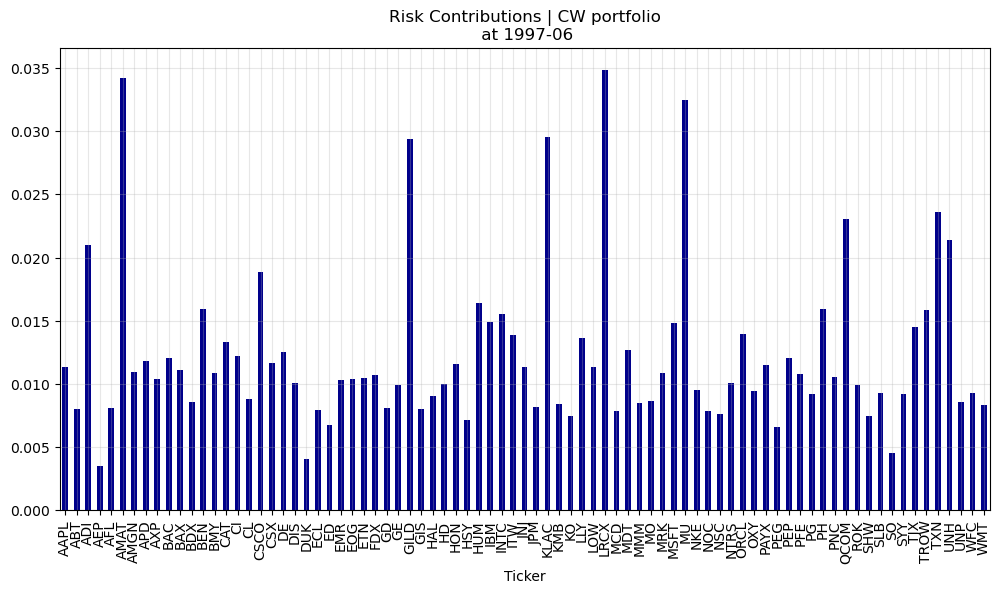

In [233]:
risk_contribs_ew = {}

for i in range(36, len(rets)):
    date = rets.index[i]

    window = rets.iloc[i-36:i]
    cov = pt.shrinkage_cov(window)

    n = rets.shape[1]
    w = np.repeat(1/n, n)

    risk_contribs_ew[date] = pt.risk_contribution(w, cov)

risk_contribs_ew = (pd.DataFrame(risk_contribs_ew).T).dropna()
ax = risk_contribs_ew.loc['1997-06'].plot.bar(figsize=(12,6), grid = True, color = 'darkblue', title = "Risk Contributions | CW portfolio\n at 1997-06")
ax.grid(alpha=0.3)

As we see, effectively, portfolio risk is not as concentrated in a few companies - contributors, but still ... it is not an equal risk contribution.

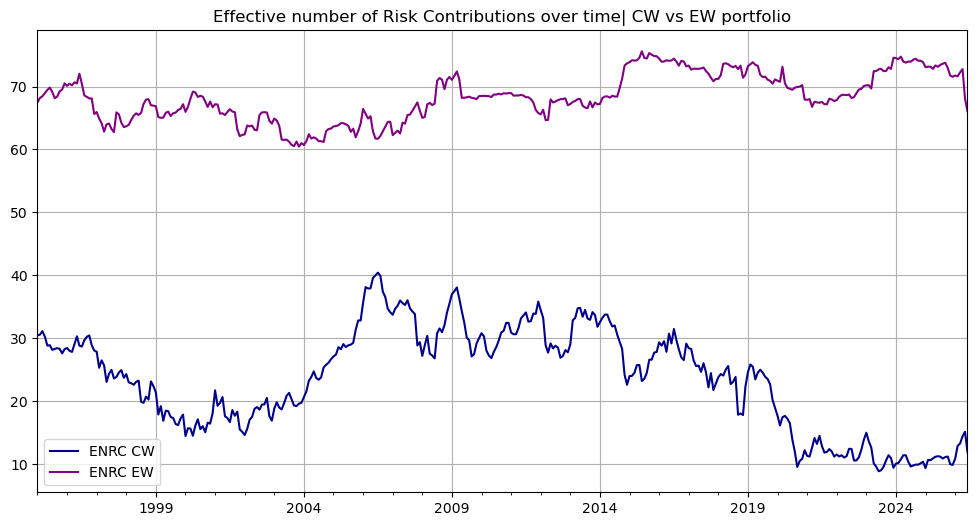

In [235]:
enrc_ew = 1 / (risk_contribs_ew**2).sum(axis=1)
enrc = pd.DataFrame({
    "ENRC CW": enrc_cw,
    "ENRC EW": enrc_ew
})
ax = enrc.plot(figsize=(12,6), grid = True, color = ['darkblue','purple'] ,
                  title = "Effective number of Risk Contributions over time| CW vs EW portfolio")

### Quick Takeaway
Equal weighting substantially improves the distribution of portfolio risk compared with capitalization weighting. The effective number of risk contributors remains around 60–75 for the EW portfolio, while the CW portfolio is much more concentrated and falls to roughly 10–15 effective risk contributors in recent years.

This shows that capitalization weighting concentrates not only capital, but also portfolio risk.

That leads us to a motivation to look for an even better improvement from risk-adjusted perspective with Equal Risk Contribution Portfolio - Risk Parity Portfolio.

### Risk Parity Weights
What if we choose the weights specifically so that each stock contributes equally to portfolio risk?
Optimizing function is given in a portfolio_toolkit:
```python
def target_risk_contribution(target, cov, max_weight=1):

    def ssd(weights, target, cov):
        return ((risk_contribution(weights, cov) - target)**2).sum()

    n = cov.shape[0]
    init_guess = np.repeat(1/n, n)

    weights_sum_to_1 = {
        "type": "eq",
        "fun": lambda weights: np.sum(weights) - 1
    }

    bounds = ((0.0, max_weight),) * n

    results = minimize(
        ssd,
        init_guess,
        args=(target, cov),
        method="SLSQP",
        options={"disp": False},
        constraints=(weights_sum_to_1,),
        bounds=bounds
    )

    if not results.success:
        raise RuntimeError(
            f"Risk-contribution optimization failed: {results.message}"
        )

    return results.x


def risk_parity_weights(cov, max_weight=1):

    n = cov.shape[0]

    return target_risk_contribution(
        target=np.repeat(1/n, n),
        cov=cov,
        max_weight=max_weight
    )


def weight_rp(r, cov_estimator=shrinkage_cov, **kwargs):

    max_weight = kwargs.pop("max_weight", 1)

    cov = cov_estimator(r, **kwargs)

    return risk_parity_weights(
        cov,
        max_weight=max_weight
    )

In [251]:
erc_weights = {}
risk_contribs_erc = {}

for i in range(36, len(rets)):
    date = rets.index[i]

    window = rets.iloc[i-36:i]

    # 1. Estimate covariance
    cov = pt.shrinkage_cov(window)

    # 2. Find ERC / risk parity weights
    w = pt.risk_parity_weights(cov)

    # 3. Store weights
    erc_weights[date] = w

    # 4. Check resulting risk contributions
    risk_contribs_erc[date] = pt.risk_contribution(w, cov)


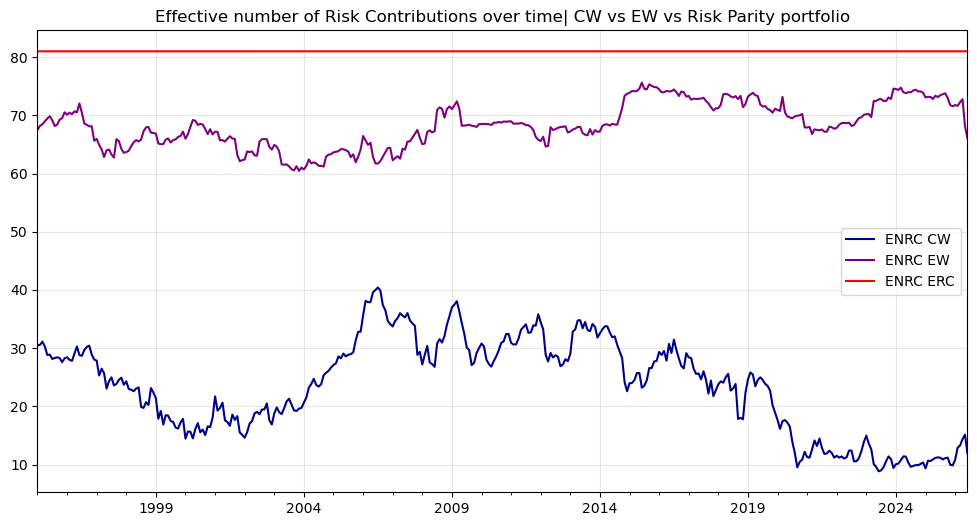

In [255]:
erc_weights_df = pd.DataFrame(erc_weights, index=rets.columns).T
risk_contribs_erc_df = pd.DataFrame(risk_contribs_erc, index=rets.columns).T
enrc_erc = 1 / (risk_contribs_erc_df**2).sum(axis=1)
enrc_full = pd.DataFrame({
    "ENRC CW": enrc_cw,
    "ENRC EW": enrc_ew,
    "ENRC ERC": enrc_erc
})
ax = enrc_full.plot(figsize=(12,6), grid = True, color = ['darkblue','purple', 'red'], 
                    title = "Effective number of Risk Contributions over time| CW vs EW vs Risk Parity portfolio")
ax.grid(alpha=0.3)

#### ERC Estimation Window

ERC weights require an estimated covariance matrix, so the first 36 months of returns are used only as an estimation window.

$$
R_{t-36}
\rightarrow
\hat{\Sigma}_t
\rightarrow
w_t^{ERC}
$$

Therefore, the first ERC portfolio return is available only after 36 months of historical data have been observed.

To ensure a fair comparison, EW, CW, ERC should all be evaluated over the same common out-of-sample period starting from the first month in which ERC weights can be formed.

In [268]:
start = erc_weights_df.index[0]

ew_rets_common = ew_rets.loc[start:]
cw_rets_common = vw_rets.loc[start:]
erc_rets_common = ((rets*erc_weights_df).sum(axis = 'columns')).loc[start:]

<Axes: title={'center': '81 Stock Index Cumulativ \n EW vs CW vs Risk Parity'}>

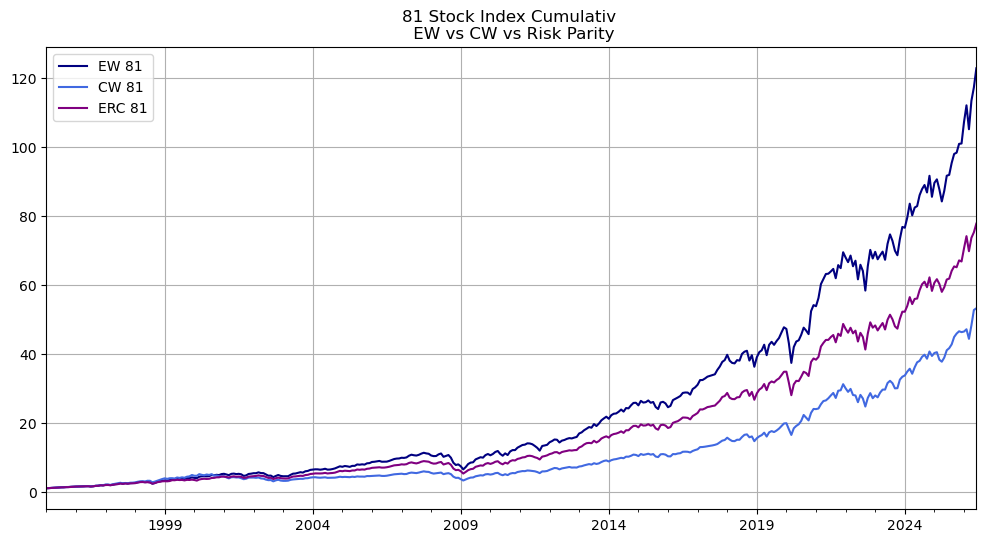

In [270]:
btr_2 = pd.DataFrame({
    "EW 81": ew_rets_common,
    "CW 81": cw_rets_common,
    "ERC 81": erc_rets_common
})
(btr_2+1).cumprod().plot(figsize = (12,6), legend = True, grid = True, color=["navy", "royalblue", "purple"], 
                         title = "81 Stock Index Cumulativ \n EW vs CW vs Risk Parity")

In [271]:
pt.summary_stats(btr_2)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW 81,0.165036,0.150295,-0.458441,4.207453,0.061937,0.091518,0.901093,-0.425269
CW 81,0.134511,0.148683,-0.422832,3.488973,0.063597,0.089173,0.728613,-0.447946
ERC 81,0.148257,0.133974,-0.530033,4.177446,0.055892,0.082399,0.884017,-0.405106


#### ERC — Key Takeaway

Because ERC requires a 36-month covariance estimation window, all three strategies are now compared over the **same shorter common sample** beginning only after sufficient historical data are available. Therefore, the EW and CW statistics shown here differ from the earlier full-sample results.

Over this common period, EW still delivers the highest annualized return and Sharpe ratio. ERC produces a lower return than EW but also the **lowest volatility and smallest maximum drawdown** of the three strategies. Its Sharpe ratio remains close to EW and clearly exceeds CW.

This suggests that ERC successfully trades some return for a more balanced and lower-risk portfolio, while CW remains the weakest strategy on a risk-adjusted basis over this sample.

In [279]:
gmv_weights = {}

for i in range(36, len(rets)):
    date = rets.index[i]

    window = rets.iloc[i-36:i]
    cov = pt.shrinkage_cov(window)

    w = pt.gmv(cov)

    gmv_weights[date] = w

gmv_weights = pd.DataFrame(gmv_weights, index=rets.columns).T

<Axes: title={'center': '81 Stock Index Cumulativ \n EW vs CW vs Risk Parity vs GMV'}>

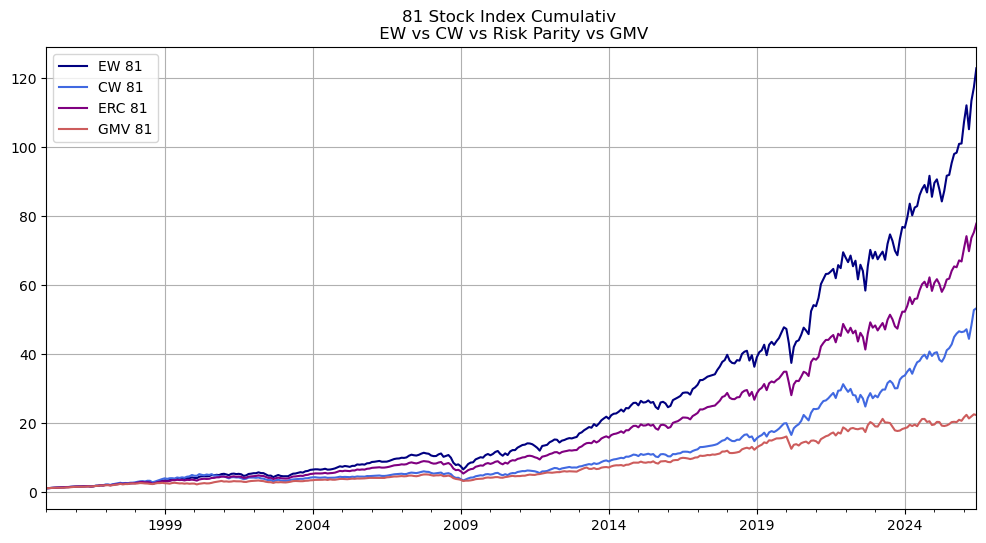

In [280]:
gmv_rets_common = ((rets * gmv_weights).dropna()).sum(axis = 'columns')
btr_3 = pd.DataFrame({
    "EW 81": ew_rets_common,
    "CW 81": cw_rets_common,
    "ERC 81": erc_rets_common,
    "GMV 81": gmv_rets_common
})

(btr_3+1).cumprod().plot(figsize = (12,6), legend = True, grid = True, color=["navy", "royalblue", "purple", "indianred"], 
                         title = "81 Stock Index Cumulativ \n EW vs CW vs Risk Parity vs GMV")

In [277]:
pt.summary_stats(btr_3)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW 81,0.165036,0.150295,-0.458441,4.207453,0.061937,0.091518,0.901093,-0.425269
CW 81,0.134511,0.148683,-0.422832,3.488973,0.063597,0.089173,0.728613,-0.447946
ERC 81,0.148257,0.133974,-0.530033,4.177446,0.055892,0.082399,0.884017,-0.405106
GMV 81,0.103540,0.121305,-0.430014,4.002371,0.052111,0.072385,0.632255,-0.379328


GMV — Key Takeaway

The Global Minimum Variance portfolio achieves its intended objective: it produces the lowest realized volatility of all four strategies and also the smallest maximum drawdown.

However, this comes at the cost of substantially lower returns. GMV earns around 10.4% annually, compared with 14.8% for ERC and 16.5% for EW, and  has the lowest Sharpe ratio in this comparison.

#### Shall we look at the GMV weights over time ?

<Axes: title={'center': 'Effective Number of Constituents - GMV'}>

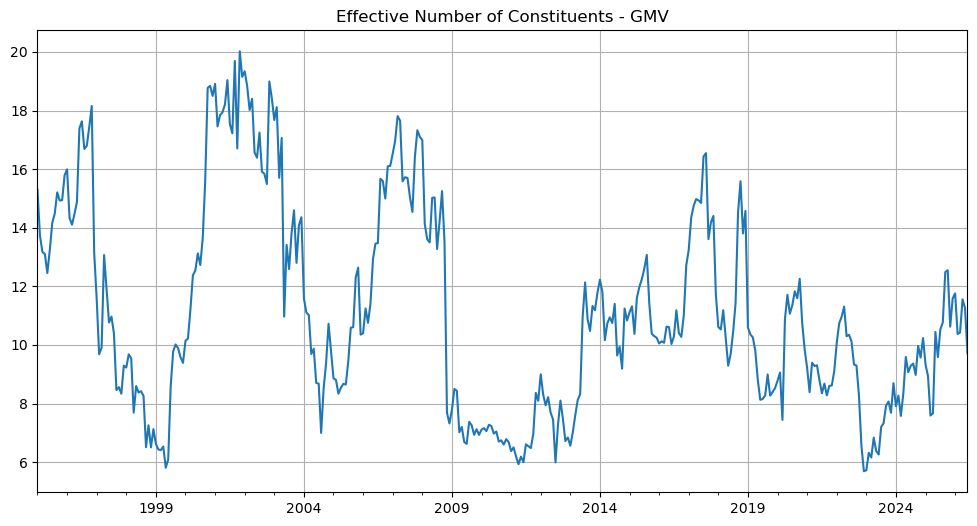

In [281]:
enc_gmv = 1 / (gmv_weights**2).sum(axis=1)

enc_gmv.plot(
    figsize=(12, 6),
    title="Effective Number of Constituents - GMV",
    grid=True
)

<Axes: title={'center': 'Largest and Second-Largest GMV Weights Over Time'}>

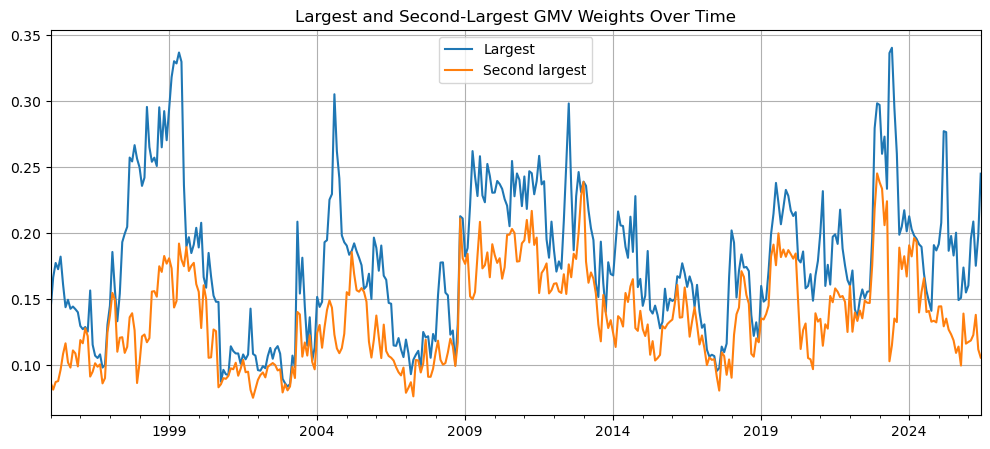

In [305]:
top2 = pd.DataFrame({
    "Largest": gmv_weights.max(axis=1),
    "Second largest": gmv_weights.apply(
        lambda row: row.nlargest(2).iloc[-1],
        axis=1
    )
})
top2.plot(figsize=(12, 5), grid=True, title="Largest and Second-Largest GMV Weights Over Time")

#### GMV Portfolio Concentration

Although GMV minimizes estimated portfolio variance, the resulting allocation can become highly concentrated. The effective number of constituents frequently falls well below the full 81-stock universe, while the largest individual positions can exceed 20% and occasionally approach 30% or more.

This suggests that the optimizer achieves low variance partly by concentrating capital in a relatively small subset of low-volatility or low-covariance stocks. Such concentration may also make the portfolio more sensitive to estimation error.

#### Constrained GMV: 10% Position Cap

To test whether excessive concentration contributes to GMV's weak performance, I impose a maximum individual stock weight of 10%.

In [295]:
import warnings

with warnings.catch_warnings():
    warnings.filterwarnings(
        "ignore",
        message="Values in x were outside bounds during a minimize step"
    )

gmv_weights_10 = {}

for i in range(36, len(rets)):
    date = rets.index[i]

    window = rets.iloc[i-36:i]
    cov = pt.shrinkage_cov(window)

    w = pt.gmv(cov, max_weight=0.1)

    gmv_weights_10[date] = w

gmv_weights_10 = pd.DataFrame(gmv_weights_10, index=rets.columns).T

In [301]:
gmv_weights_10.max().max()

0.1

<Axes: >

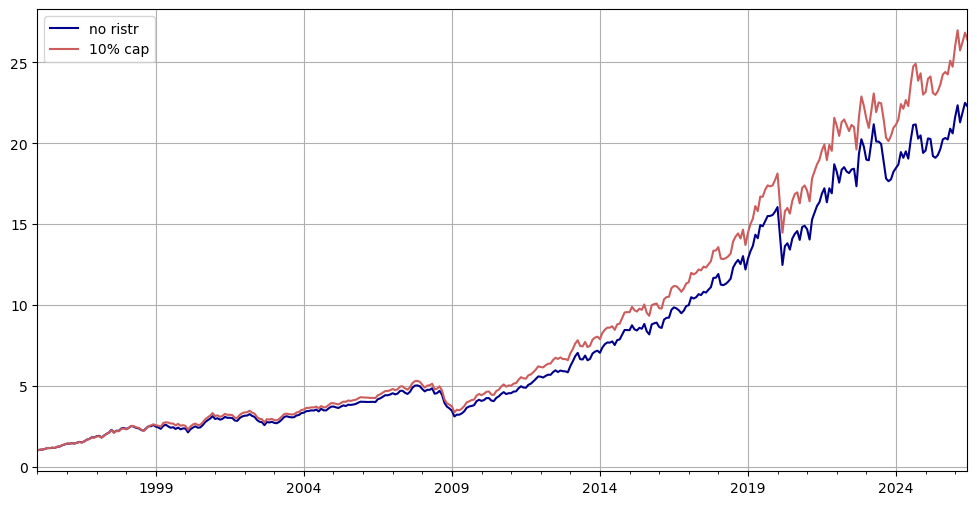

In [308]:
gmv_rets_common_10 = ((rets * gmv_weights_10).dropna()).sum(axis = 'columns')

gmv_btr = pd.DataFrame({
    'no ristr ': gmv_rets_common,
    '10% cap' : gmv_rets_common_10
})

(gmv_btr+1).cumprod().plot(figsize = (12,6), color=["darkblue", "indianred"], grid = True)

In [304]:
pt.summary_stats(gmv_btr)

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
no ristr,0.103540,0.121305,-0.430014,4.002371,0.052111,0.072385,0.632255,-0.379328
10% cap,0.109503,0.118743,-0.403146,3.849013,0.050256,0.070913,0.688989,-0.363975


The constrained GMV portfolio performs somewhat better than the unrestricted version: annualized return and Sharpe ratio increase, while volatility and maximum drawdown remain slightly lower. 

However, the improvement is not large enough to close the performance gap with EW or ERC, indicating that concentration alone does not fully explain GMV's underperformance.

## What is this all about ?

1. **EW beats CW not only because it spreads capital more evenly, but in this universe it also distributes risk much more broadly.**

2. ERC goes one step further by explicitly equalizing risk and achieves a strong return-risk compromise. Both Risk Parity turned to be more favourable portfolios. 

3. GMV succeeds at minimizing volatility, but its optimization generates concentrated defensive portfolios and substantial return sacrifice.

## Next: Ex-post covariance diagnostic

The analysis above evaluates portfolio construction in a realistic out-of-sample setting, where covariance matrices must be estimated using only past information. But the poor GMV performance made me think: how much of the observed performance is driven by covariance estimation error?

To explore this, the next notebook considers an ex-post setting in which the realized covariance structure is treated as if it were known in advance.

We will compare the different weighting schemes using ex-post covariance information, treating realized volatility and correlations as if they were known in advance.

In [314]:
btr_1.to_csv("../data/processed/rets_81_ew_cw.csv")
rets.to_csv("../data/processed/rets_81.csv")